COMPROBACION: regla vieja, N=50, m=3, s=2, T=6000, contra referencias/Ref Fase 2


  sin puntaje: np.array_equal = True  (forma (100, 101))  [Md_estrategias_sin_recompensa_todas_las_cadenas.csv]


  con puntaje: np.array_equal = True  (forma (100, 101))  [Md_2estrategias_con_puntaje_todas_las_cadenas.csv]



CORRIDA: regla_nueva (OPCION_VACIA_GANA = False), N=101, s=2, K=3, T=6000, 100 cadenas


Caso A (m=2, sin puntaje): opcion vacia=0  N0=0: 0  N1=0: 0  N0=N1=0 (precio repetido): 0  todos en la misma opcion: 0  moneda=40435  de 600000 turnos.  Destacada: cadena 33, semilla 2658800735, recorrido 675.1980  [4.9 s]


Caso B (m=2, con puntaje): opcion vacia=0  N0=0: 0  N1=0: 0  N0=N1=0 (precio repetido): 0  todos en la misma opcion: 0  moneda=35344  de 600000 turnos.  Destacada: cadena 77, semilla 4143265232, recorrido 42.2772  [5.8 s]


Caso C (m=3, sin puntaje): opcion vacia=0  N0=0: 0  N1=0: 0  N0=N1=0 (precio repetido): 0  todos en la misma opcion: 0  moneda=41404  de 600000 turnos.  Destacada: cadena 82, semilla 3939606599, recorrido 215.3564  [4.9 s]


Caso D (m=3, con puntaje): opcion vacia=0  N0=0: 0  N1=0: 0  N0=N1=0 (precio repetido): 0  todos en la misma opcion: 0  moneda=84085  de 600000 turnos.  Destacada: cadena 15, semilla 826721091, recorrido 64.5149  [5.8 s]



Guardado: csv\resumen_fase9.csv

Graficas del caso A:


  Guardado: graficas\Fase9_precios_conjunto_casoA_N101_m2_s2_sin_puntaje_T6000_regla_nueva_sin_burnin.png


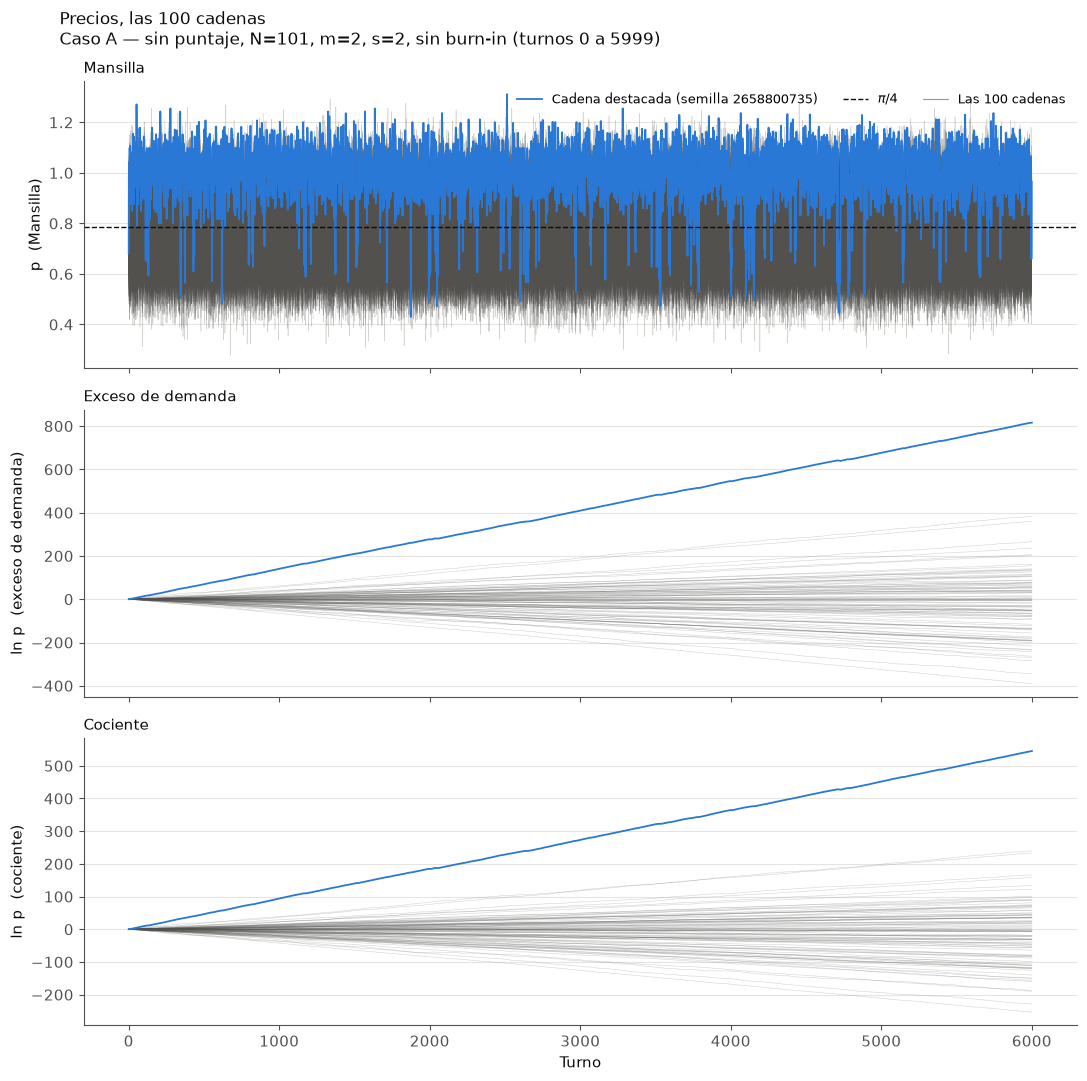

  Guardado: graficas\Fase9_precios_detalle_casoA_N101_m2_s2_sin_puntaje_T6000_regla_nueva_sin_burnin.png


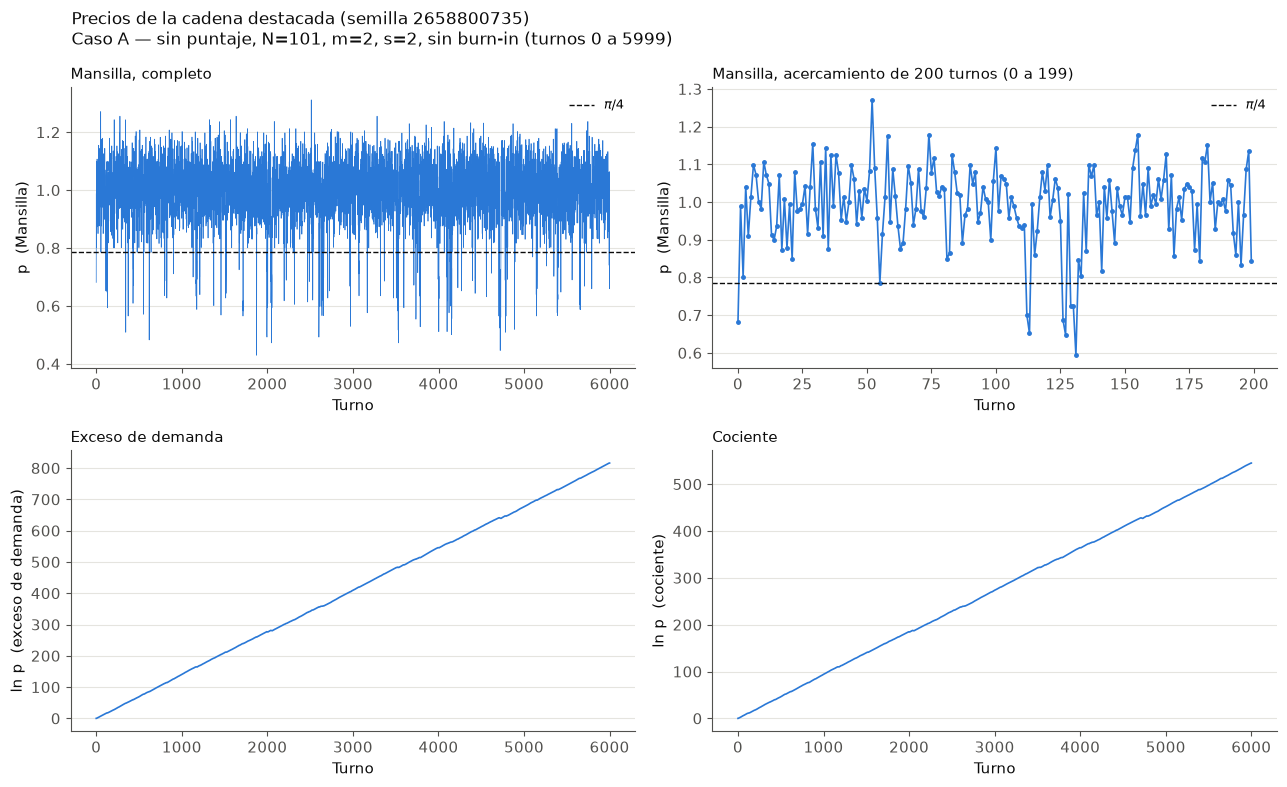

  Guardado: graficas\Fase9_precios_conjunto_casoA_N101_m2_s2_sin_puntaje_T6000_regla_nueva_con_burnin1000.png


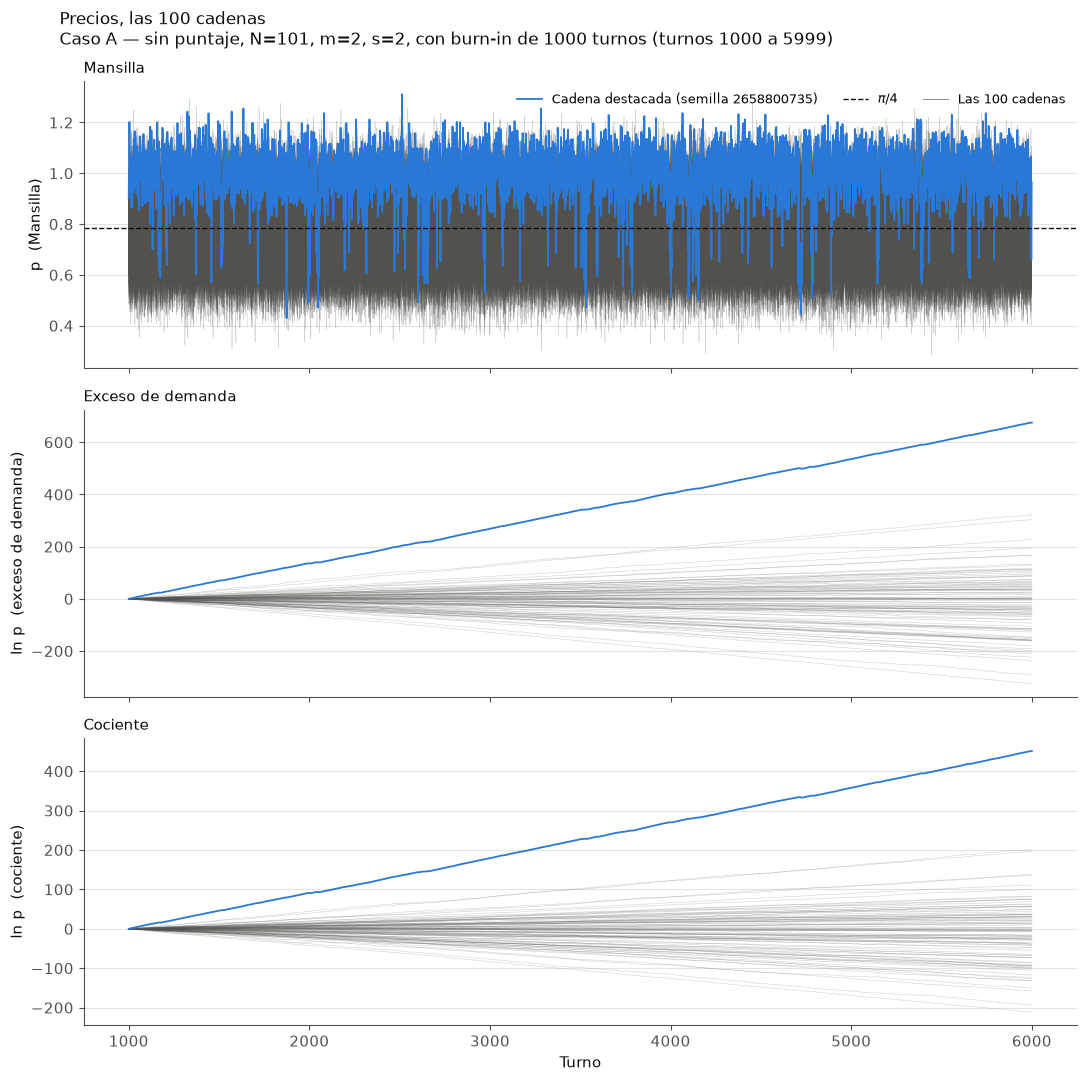

  Guardado: graficas\Fase9_precios_detalle_casoA_N101_m2_s2_sin_puntaje_T6000_regla_nueva_con_burnin1000.png


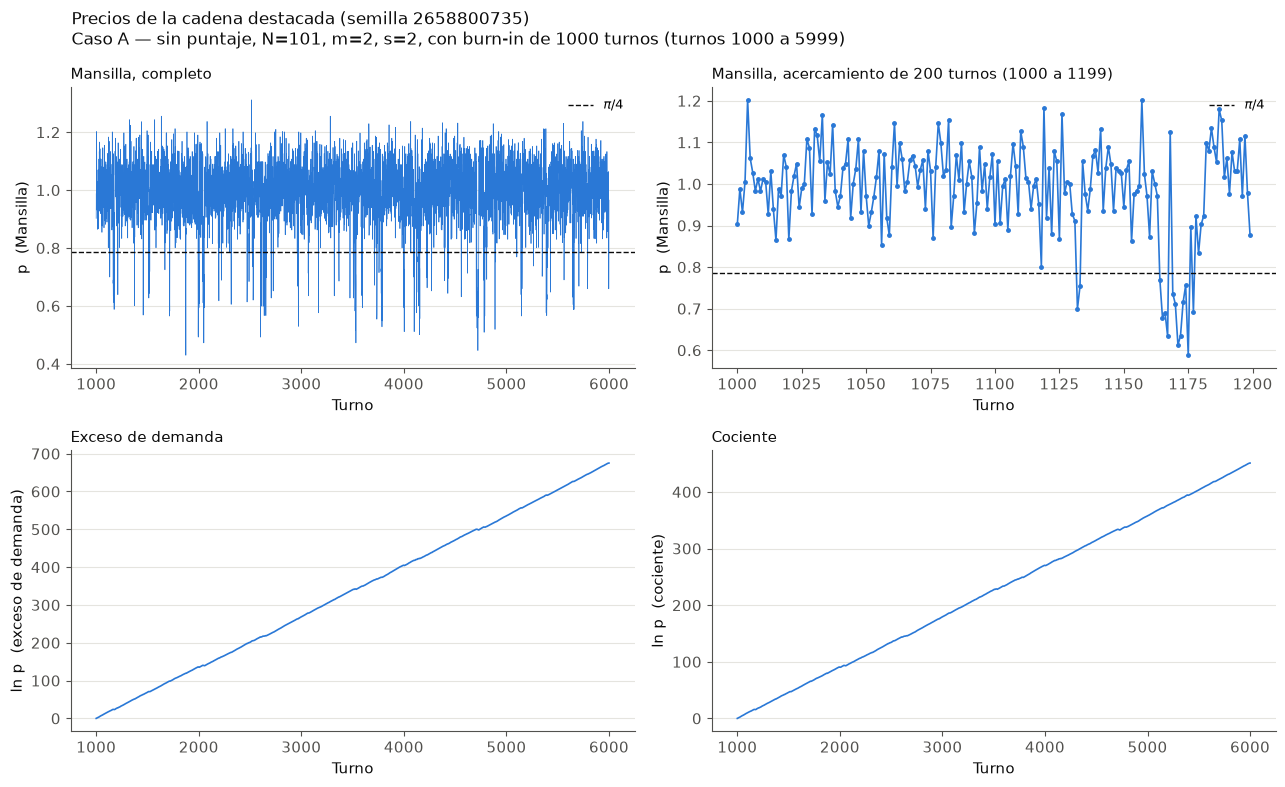


Graficas del caso B:


  Guardado: graficas\Fase9_precios_conjunto_casoB_N101_m2_s2_con_puntaje_T6000_regla_nueva_sin_burnin.png


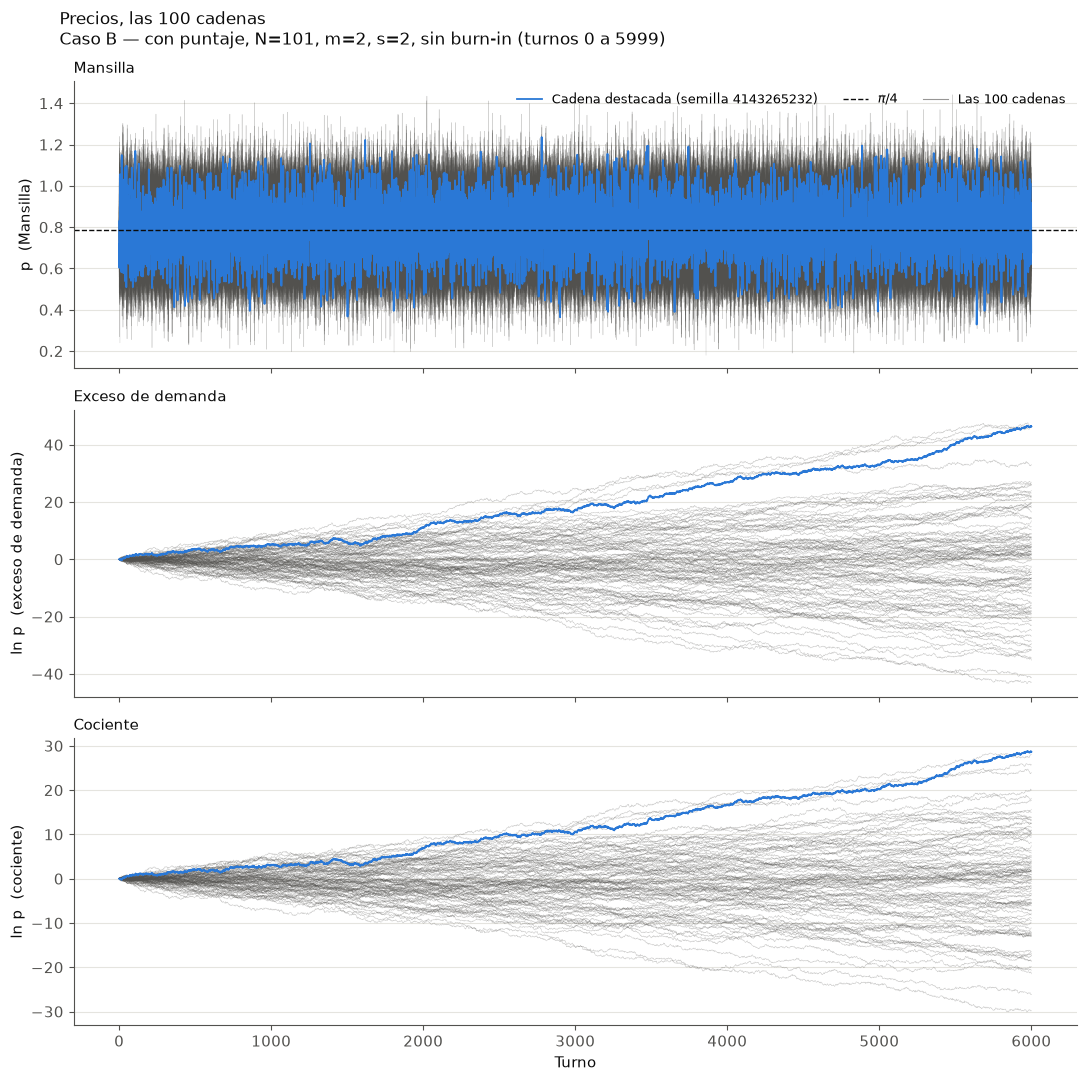

  Guardado: graficas\Fase9_precios_detalle_casoB_N101_m2_s2_con_puntaje_T6000_regla_nueva_sin_burnin.png


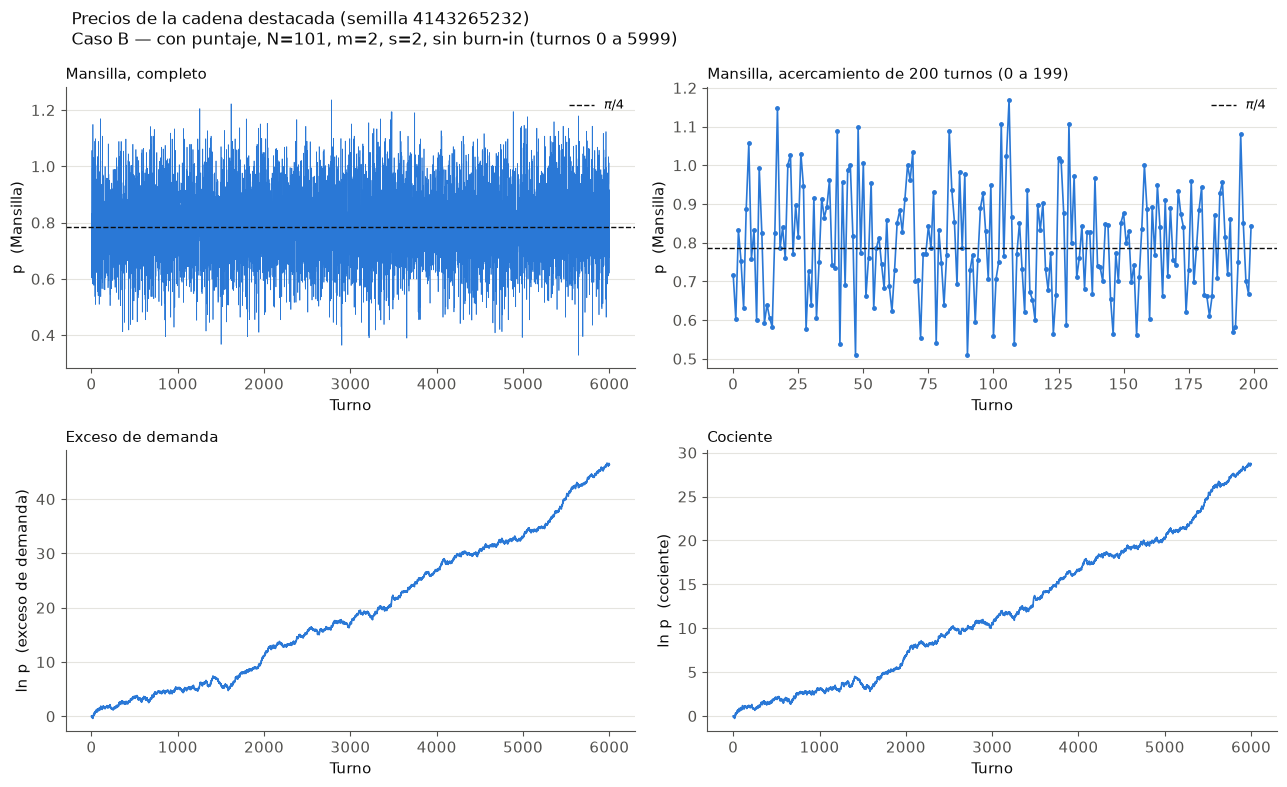

  Guardado: graficas\Fase9_precios_conjunto_casoB_N101_m2_s2_con_puntaje_T6000_regla_nueva_con_burnin1000.png


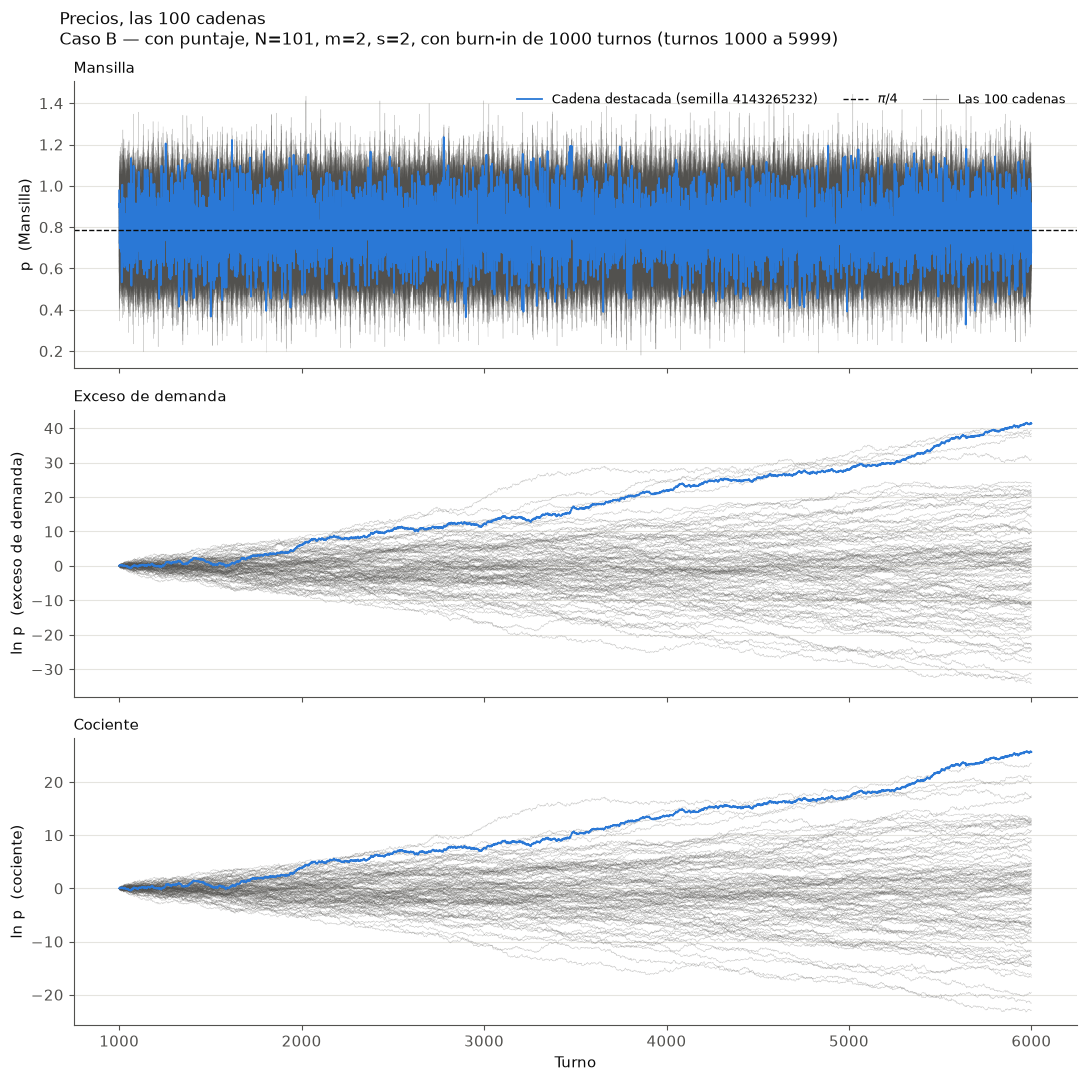

  Guardado: graficas\Fase9_precios_detalle_casoB_N101_m2_s2_con_puntaje_T6000_regla_nueva_con_burnin1000.png


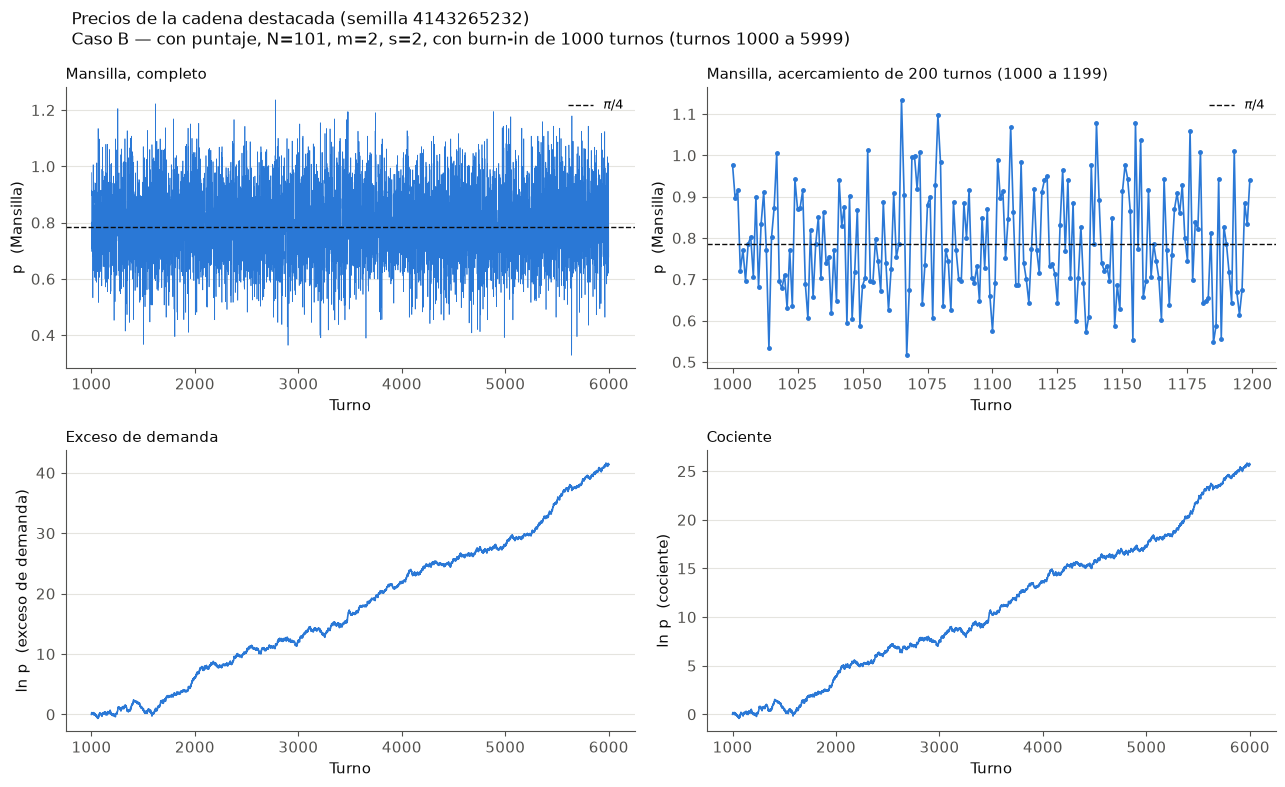


Graficas del caso C:


  Guardado: graficas\Fase9_precios_conjunto_casoC_N101_m3_s2_sin_puntaje_T6000_regla_nueva_sin_burnin.png


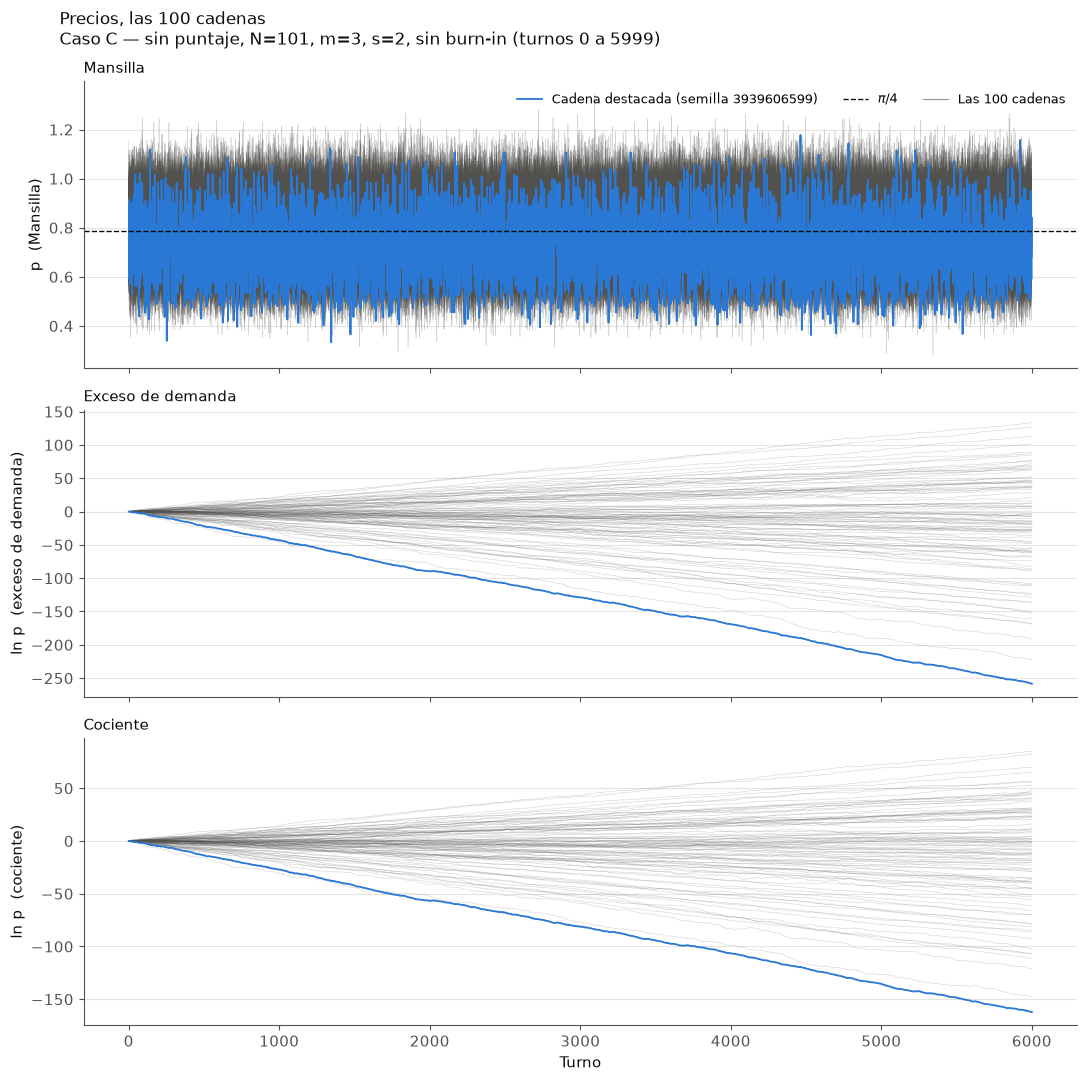

  Guardado: graficas\Fase9_precios_detalle_casoC_N101_m3_s2_sin_puntaje_T6000_regla_nueva_sin_burnin.png


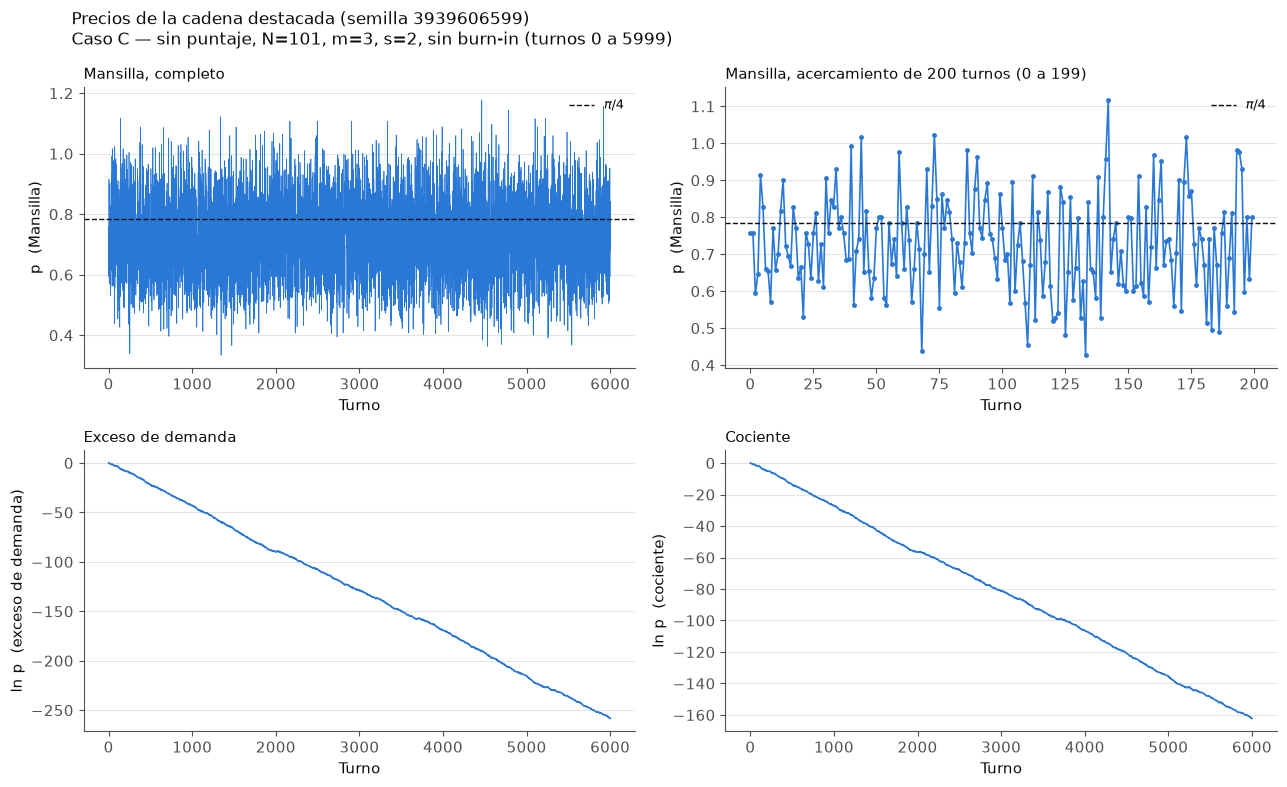

  Guardado: graficas\Fase9_precios_conjunto_casoC_N101_m3_s2_sin_puntaje_T6000_regla_nueva_con_burnin1000.png


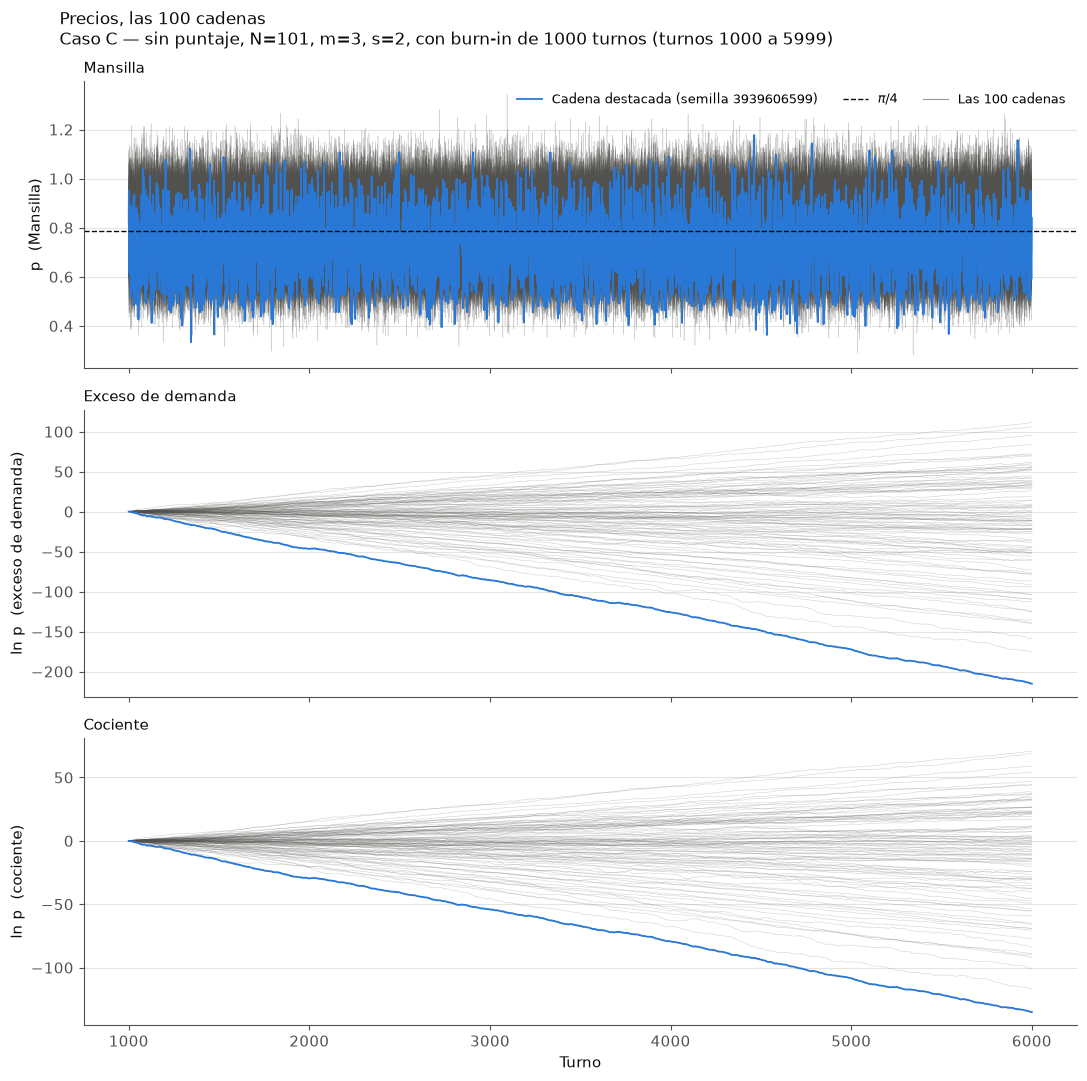

  Guardado: graficas\Fase9_precios_detalle_casoC_N101_m3_s2_sin_puntaje_T6000_regla_nueva_con_burnin1000.png


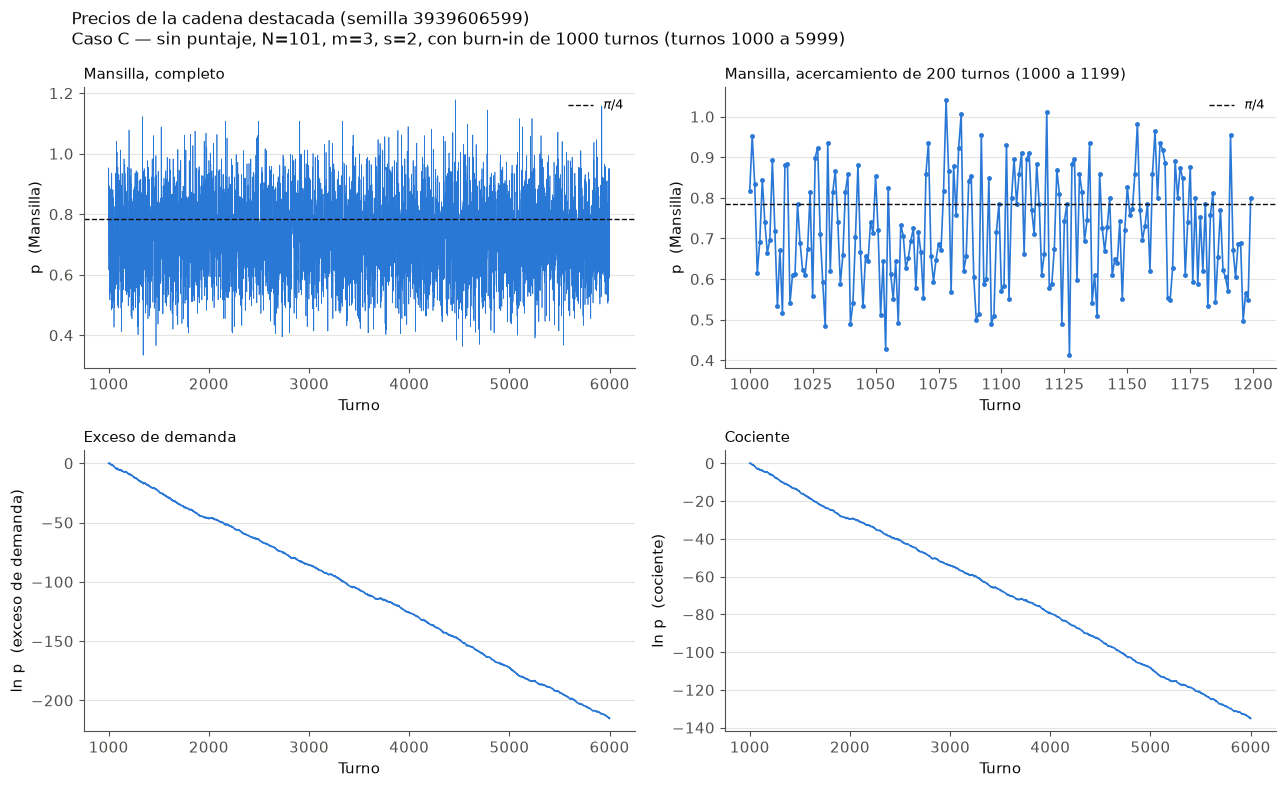


Graficas del caso D:


  Guardado: graficas\Fase9_precios_conjunto_casoD_N101_m3_s2_con_puntaje_T6000_regla_nueva_sin_burnin.png


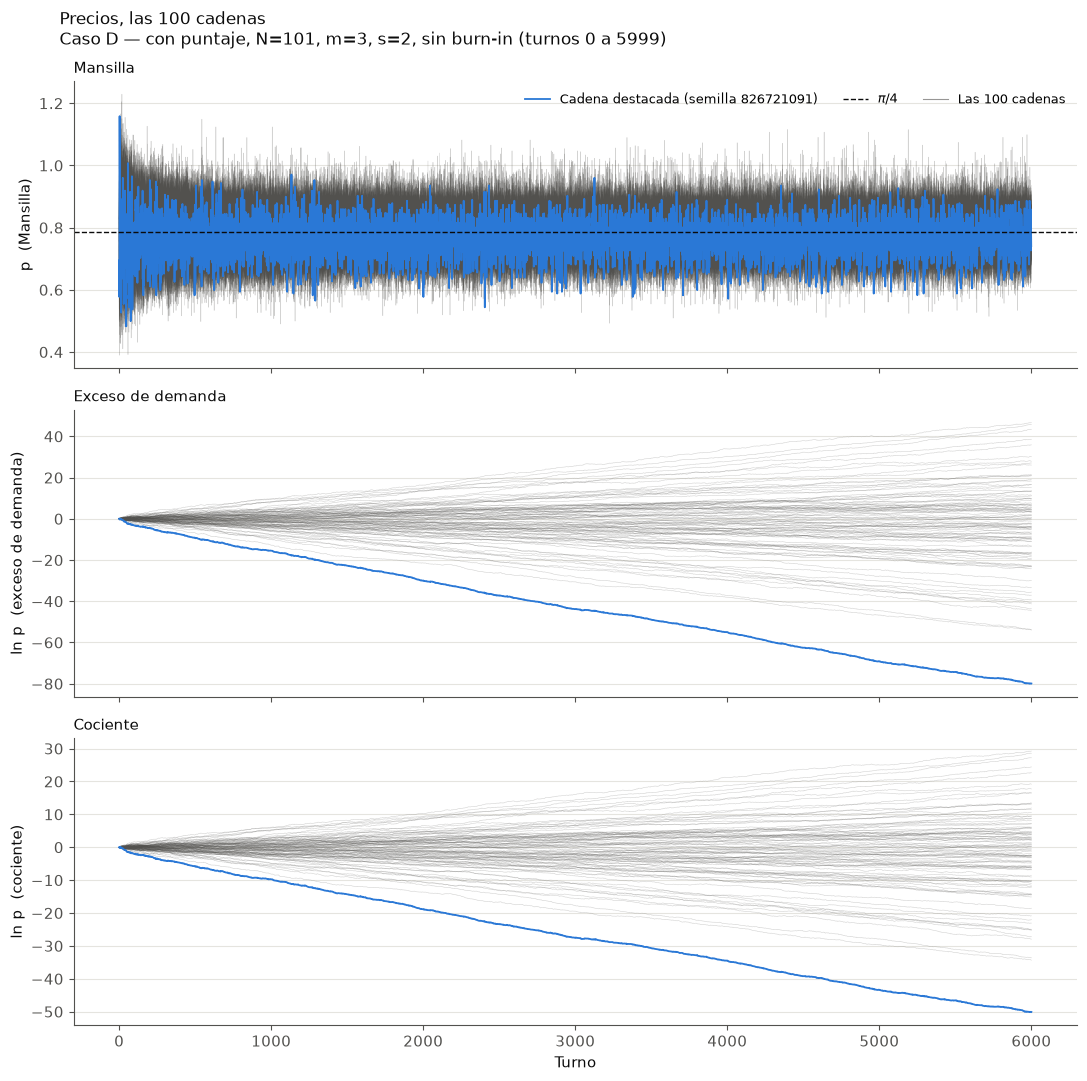

  Guardado: graficas\Fase9_precios_detalle_casoD_N101_m3_s2_con_puntaje_T6000_regla_nueva_sin_burnin.png


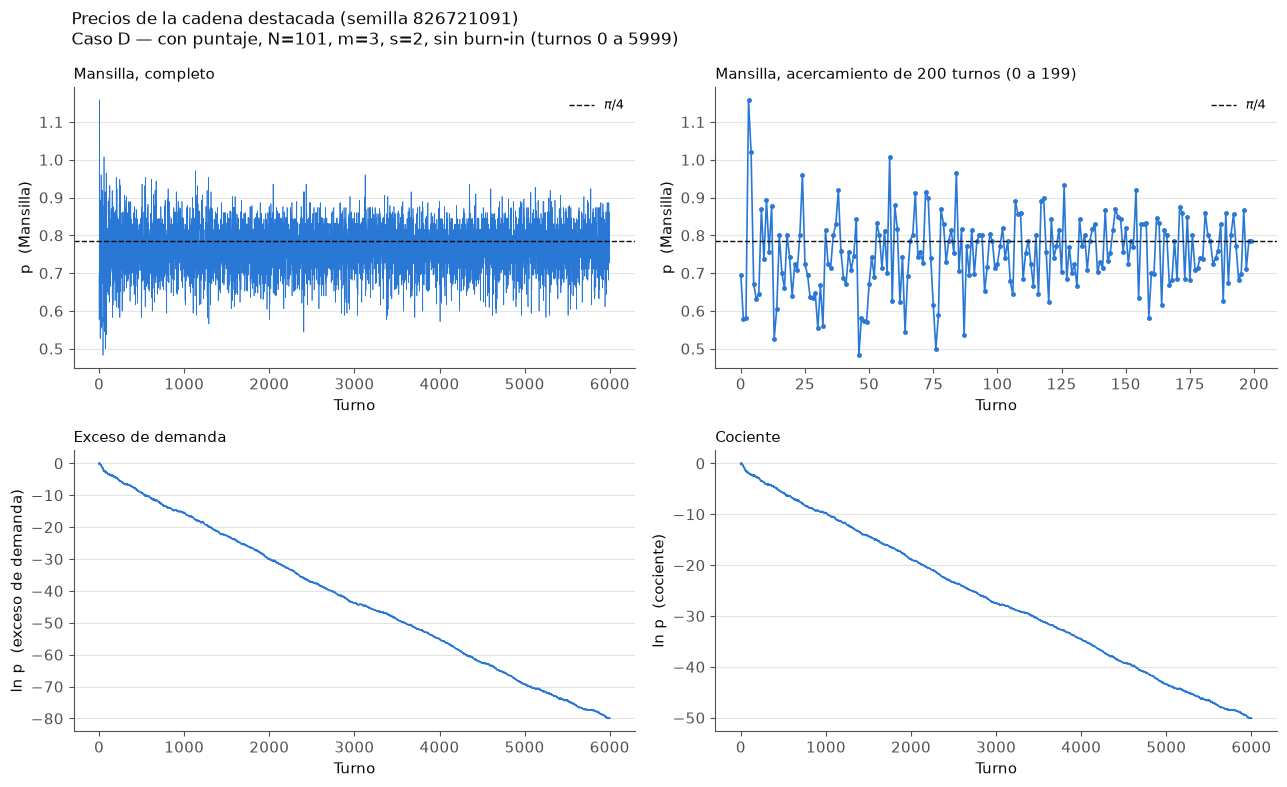

  Guardado: graficas\Fase9_precios_conjunto_casoD_N101_m3_s2_con_puntaje_T6000_regla_nueva_con_burnin1000.png


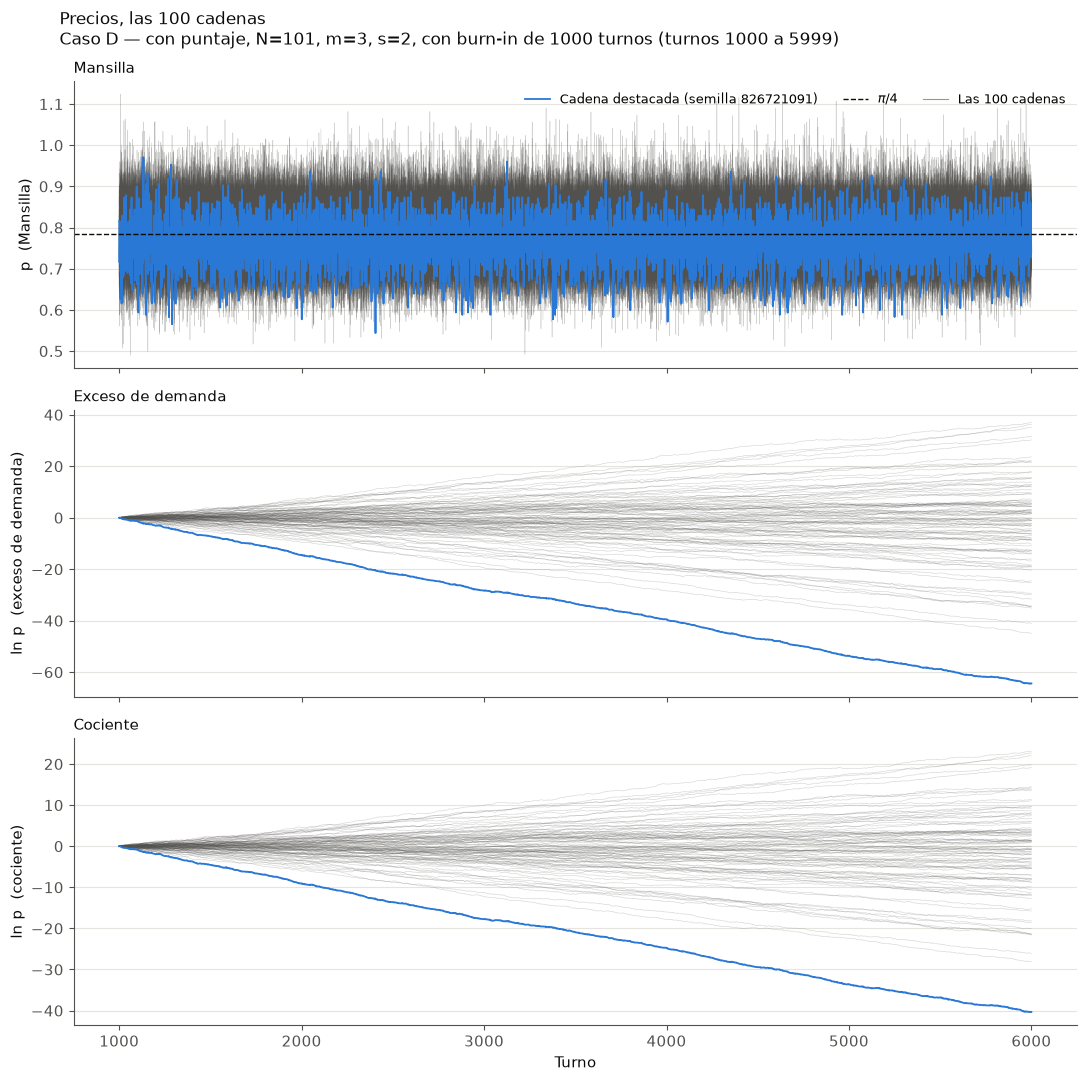

  Guardado: graficas\Fase9_precios_detalle_casoD_N101_m3_s2_con_puntaje_T6000_regla_nueva_con_burnin1000.png


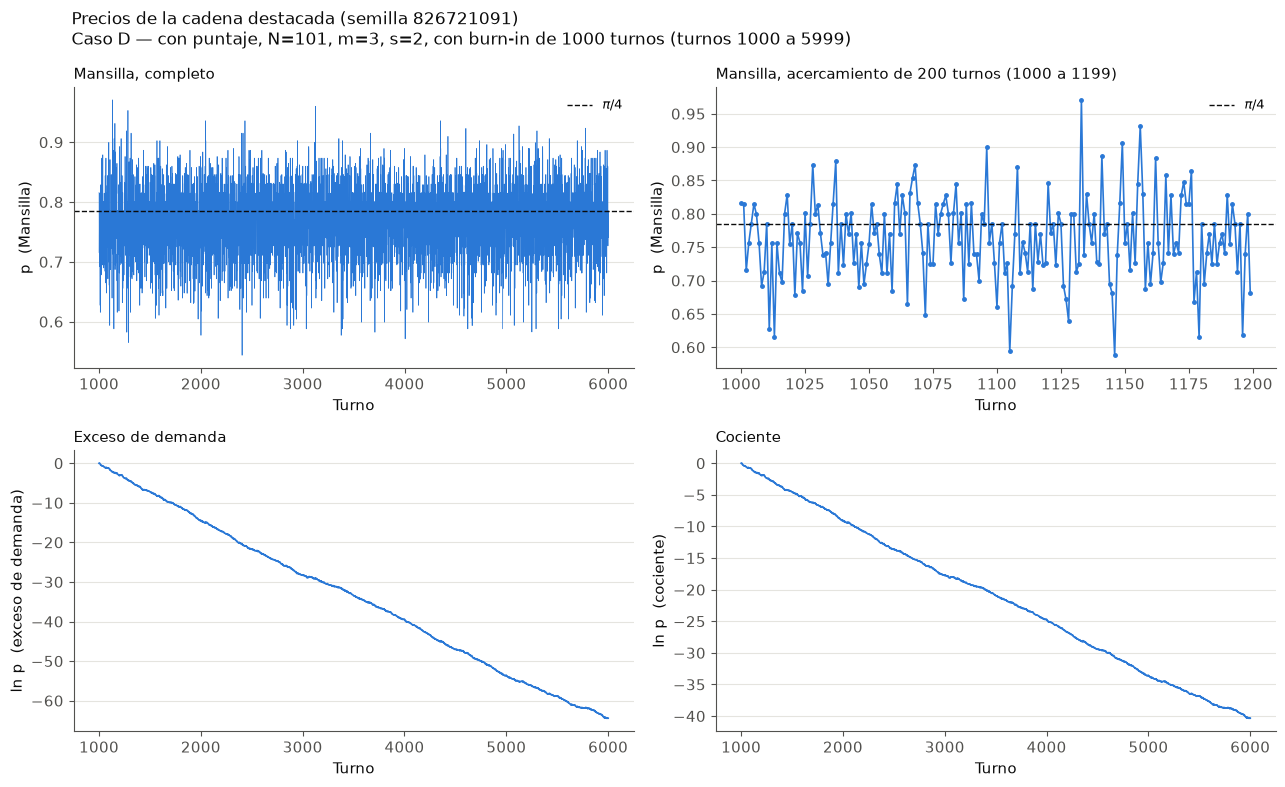


Listo. Tiempo total: 1.8 min


In [1]:
"""
FASE 9 - Minority game de tres decisiones: conteos por turno y precios
======================================================================
Tesis: Complejidad e informacion en un minority game con opcion de abstencion

Alfabeto: 0 = comprar, 1 = vender, 2 = abstenerse

Copia de notebooks/Fase 2/Segundo_paso_tres_casos. Los agentes "sin puntaje"
y "con puntaje" son los de ese notebook. Lo unico que se les agrego:
  - guardan en cada turno N0, N1, N2 (cuantos agentes eligieron cada opcion),
    el simbolo ganador y si el turno se decidio con moneda. Este registro no
    consume numeros aleatorios;
  - reciben el parametro OPCION_VACIA_GANA.

Regla de ganador:
  OPCION_VACIA_GANA = True  -> regla vieja: gana la opcion menos elegida,
                               contando tambien una opcion con cero agentes.
  OPCION_VACIA_GANA = False -> regla nueva: una opcion sin agentes no cuenta.
                               Gana la menos elegida entre las que tienen al
                               menos un agente. Si todos eligen la misma
                               opcion, gana esa opcion y ganan todos.
  En las dos reglas, un empate entre las menos elegidas se decide al azar.

Que hace este codigo:
  0. COMPROBACION: con la regla vieja y los parametros de la Fase 2 (N = 50,
     m = 3), M(d) de todas las cadenas debe ser identico al de
     referencias/Ref Fase 2. Si no, el notebook se detiene.
  1. Corre los 4 casos (m = 2 y 3, sin y con puntaje), 100 cadenas cada uno.
  2. Con los conteos calcula tres precios:
       Mansilla:           p_t = arctan(N0/N1)
       Exceso de demanda:  ln p_{t+1} = ln p_t + (N0 - N1) / LAMBDA_EXCESO
       Cociente:           ln p_{t+1} = ln p_t + ln[(N0+1)/(N1+1)] / LAMBDA_COCIENTE
  3. Dibuja las graficas sin burn-in y con burn-in, y guarda los CSV.

En esta fase NO se calcula M(d) (solo en la comprobacion), ni rendimientos,
volatilidad o fraccion de abstencion.

Las funciones simular_sin_recompensa, simular_con_puntaje e informacion_mutua
son las de la Fase 2, con los unicos cambios descritos arriba.
"""

import io
import os
import time

import numpy as np
import matplotlib.pyplot as plt

try:
    from joblib import Parallel, delayed
    HAY_JOBLIB = True
except ImportError:
    HAY_JOBLIB = False


# =====================================================================
# OPCIONES
# =====================================================================
# Las graficas SIEMPRE se muestran en el notebook.
# True  = ademas se guardan como PNG en CARPETA_GRAFICAS
DESCARGAR_GRAFICAS = True

# True  = se guardan los 5 CSV en CARPETA_CSV
GUARDAR_CSV        = True

# True  = regla vieja (una opcion vacia gana)
# False = regla nueva (una opcion vacia no cuenta)
OPCION_VACIA_GANA  = False

# True = antes de todo, compara la regla vieja contra referencias/Ref Fase 2
HACER_COMPROBACION = True

CARPETA_CSV      = "csv"
CARPETA_GRAFICAS = "graficas"
CARPETA_REFERENCIA = os.path.join("..", "..", "referencias", "Ref Fase 2")  # solo se lee

#   -1 -> usa TODOS los nucleos     1 -> un solo nucleo
N_NUCLEOS = -1


# =====================================================================
# PARAMETROS
# =====================================================================
SEMILLA_MAESTRA = 1907443528   # genera las 100 semillas de forma reproducible
N_CADENAS = 100                # numero de cadenas (semillas distintas)

N       = 101    # agentes
S       = 2      # estrategias por agente
K       = 3      # tamano del alfabeto
T       = 6000   # turnos registrados, desde el primero
BURN_IN = 1000   # solo afecta a las graficas; los CSV guardan todo

CASOS = [{"caso": "A", "m": 2, "puntaje": False}, {"caso": "B", "m": 2, "puntaje": True}, {"caso": "C", "m": 3, "puntaje": False}, {"caso": "D", "m": 3, "puntaje": True}]

LAMBDA_EXCESO   = N               # divide a (N0 - N1)
LAMBDA_COCIENTE = np.log(N + 1)   # divide a ln[(N0+1)/(N1+1)]

ZOOM = 200       # turnos del acercamiento del precio de Mansilla

# --- parametros de la comprobacion (los de la Fase 2) ---
N_COMP, M_COMP, D_MAX = 50, 3, 100


# =====================================================================
# REGLA DE GANADOR
# =====================================================================
def regla_ganador(conteos, rng, opcion_vacia_gana):
    """Devuelve el simbolo ganador y si se decidio con moneda.

    Regla vieja: gana el minimo de las K opciones (una vacia cuenta).
    Regla nueva: gana el minimo entre las opciones con al menos un agente.
    El desempate usa rng.choice igual que el codigo de la Fase 2, asi que
    se consume la misma cantidad de numeros aleatorios en las dos reglas.
    """
    if opcion_vacia_gana:
        minimo = conteos.min()
    else:
        minimo = conteos[conteos > 0].min()
    empatados = np.flatnonzero(conteos == minimo)
    return int(rng.choice(empatados)), len(empatados) > 1


# =====================================================================
# s ESTRATEGIAS POR AGENTE, SIN PUNTAJE  (Fase 2 + registro de conteos)
# =====================================================================
def simular_sin_recompensa(N, m, s, K, T, semilla, opcion_vacia_gana):
    """Corre una partida con agentes que tienen s estrategias pero no
    las califican.

    Todo es igual al codigo base, excepto que se quita la recompensa:
    los puntajes valen 0 siempre. Entonces en el paso 2 las s estrategias
    de cada agente estan empatadas y el ruido decide cual se usa. Es decir,
    en cada ciclo cada agente toma al azar una de sus estrategias y hace
    lo que esa estrategia dice para la historia actual.

    Diferencia clave con los agentes ingenuos: aqui la decision SI depende
    de la memoria, porque las estrategias son tablas que responden a la
    historia de los ultimos m ganadores.
    """
    rng = np.random.default_rng(semilla)
    N_HIST = K ** m

    # --- agentes (igual que el codigo base) ---
    # estrategias[i, j, h] = accion que la estrategia j del agente i
    #                        recomienda ante la historia con indice h
    estrategias = rng.integers(0, K, size=(N, s, N_HIST))

    # puntajes[i, j]: se quedan en 0 porque no hay recompensa
    puntajes = np.zeros((N, s))

    # --- memoria: los m datos que el mercado tiene "al nacer" ---
    historia = rng.integers(0, K, size=m)

    pesos = K ** np.arange(m - 1, -1, -1)   # convierte historia -> indice
    indices = np.arange(N)

    serie_ganadores = np.zeros(T, dtype=int)
    conteos_por_turno = np.zeros((T, K), dtype=np.int32)   # N0, N1, N2
    con_moneda = np.zeros(T, dtype=bool)

    for t in range(T):

        # 1. que situacion estan viendo los agentes
        idx = int(historia @ pesos)

        # 2. cada agente toma su estrategia con mas puntos.
        #    Como todos los puntajes valen 0, el ruido decide al azar.
        mejor = np.argmax(puntajes + rng.random((N, s)) * 0.5, axis=1)

        # 3. consulta esa estrategia en la historia actual y actua
        acciones = estrategias[indices, mejor, idx]

        # 4. se cuenta cuantos eligieron cada opcion
        conteos = np.bincount(acciones, minlength=K)

        # 5. gana la minoria (segun la regla elegida)
        ganador, hubo_moneda = regla_ganador(conteos, rng, opcion_vacia_gana)

        # 6. (SIN RECOMPENSA: en el codigo base aqui se sumaban puntos)

        # 7. registrar desde el primer ciclo
        serie_ganadores[t] = ganador
        conteos_por_turno[t] = conteos
        con_moneda[t] = hubo_moneda

        # 8. la memoria se desplaza: entra el ganador, sale el mas viejo
        historia = np.roll(historia, -1)
        historia[-1] = ganador

    return serie_ganadores, conteos_por_turno, con_moneda


# =====================================================================
# s ESTRATEGIAS POR AGENTE, CON PUNTAJE  (Fase 2 + registro de conteos)
# =====================================================================
def simular_con_puntaje(N, m, s, K, T, semilla, opcion_vacia_gana):
    """Corre una partida con las reglas del codigo base, sin burn-in.

    Cada agente tiene s estrategias. En cada ciclo usa la que tiene mas
    puntos (los empates se rompen al azar), y al final del ciclo todas
    las estrategias que habrian acertado al ganador reciben un punto.

    Devuelve la serie de ganadores, cuantas veces acerto cada agente, los
    conteos N0, N1, N2 de cada turno y si el turno se decidio con moneda.
    """
    rng = np.random.default_rng(semilla)
    N_HIST = K ** m

    # --- agentes (igual que el codigo base) ---
    # estrategias[i, j, h] = accion que la estrategia j del agente i
    #                        recomienda ante la historia con indice h
    estrategias = rng.integers(0, K, size=(N, s, N_HIST))

    # puntajes[i, j] = puntos virtuales (casos de exito) de esa estrategia
    puntajes = np.zeros((N, s))

    # --- memoria: los m datos que el mercado tiene "al nacer" ---
    historia = rng.integers(0, K, size=m)

    pesos = K ** np.arange(m - 1, -1, -1)   # convierte historia -> indice
    indices = np.arange(N)

    serie_ganadores = np.zeros(T, dtype=int)
    conteos_por_turno = np.zeros((T, K), dtype=np.int32)   # N0, N1, N2
    con_moneda = np.zeros(T, dtype=bool)
    exitos_agente = np.zeros(N, dtype=int)

    for t in range(T):

        # 1. que situacion estan viendo los agentes
        idx = int(historia @ pesos)

        # 2. cada agente toma su estrategia con mas puntos.
        #    El ruido < 1 rompe empates al azar sin alterar el orden
        #    entre puntajes enteros distintos.
        mejor = np.argmax(puntajes + rng.random((N, s)) * 0.5, axis=1)

        # 3. consulta esa estrategia en la historia actual y actua
        acciones = estrategias[indices, mejor, idx]

        # 4. se cuenta cuantos eligieron cada opcion
        conteos = np.bincount(acciones, minlength=K)

        # 5. gana la minoria (segun la regla elegida)
        ganador, hubo_moneda = regla_ganador(conteos, rng, opcion_vacia_gana)

        # 6. se premian TODAS las estrategias que hubieran acertado,
        #    se hayan jugado o no (regla del codigo base / PRE 62).
        puntajes += (estrategias[:, :, idx] == ganador)

        # 7. registrar desde el primer ciclo
        serie_ganadores[t] = ganador
        conteos_por_turno[t] = conteos
        con_moneda[t] = hubo_moneda
        exitos_agente += (acciones == ganador)

        # 8. la memoria se desplaza: entra el ganador, sale el mas viejo
        historia = np.roll(historia, -1)
        historia[-1] = ganador

    return serie_ganadores, exitos_agente, conteos_por_turno, con_moneda


# =====================================================================
# FUNCION DE INFORMACION MUTUA  (Fase 2; aqui solo se usa en la comprobacion)
# =====================================================================
def informacion_mutua(serie, d, K):
    """M(d) = sum_{a,b} P_ab(d) * log2[ P_ab(d) / (P_a * P_b) ]

    P_ab(d): probabilidad de encontrar el simbolo a y, d lugares despues,
             el simbolo b. Se estima contando todos los pares
             (serie[i], serie[i+d]) de la cadena.
    P_a:     densidad del simbolo a en la cadena completa (como dice
             Mansilla: "the density of the symbol alpha").

    La suma corre sobre los K*K = 9 pares (a, b). Los pares que nunca
    aparecen (P_ab = 0) no aportan, porque 0 * log(0) = 0.
    """
    x = serie[:-d]          # simbolo alpha
    y = serie[d:]           # simbolo beta, d lugares despues
    n_pares = len(x)

    # probabilidades conjuntas P_ab(d): matriz K x K
    conjunta = np.bincount(x * K + y, minlength=K * K).reshape(K, K) / n_pares

    # densidades P_a de cada simbolo en toda la cadena
    densidad = np.bincount(serie, minlength=K) / len(serie)
    producto = np.outer(densidad, densidad)      # P_a * P_b

    M_d = 0.0
    for a in range(K):
        for b in range(K):
            if conjunta[a, b] > 0:
                M_d += conjunta[a, b] * np.log2(conjunta[a, b] / producto[a, b])
    return M_d


# =====================================================================
# UNA CADENA Y UN CASO COMPLETO
# =====================================================================
def correr_cadena(N, m, s, K, T, semilla, puntaje, opcion_vacia_gana):
    if puntaje:
        serie, _, conteos, moneda = simular_con_puntaje(N, m, s, K, T, semilla,
                                                        opcion_vacia_gana)
    else:
        serie, conteos, moneda = simular_sin_recompensa(N, m, s, K, T, semilla,
                                                        opcion_vacia_gana)
    return serie, conteos, moneda


def correr_caso(N, m, s, K, T, semillas, puntaje, opcion_vacia_gana, n_nucleos):
    """Corre todas las cadenas. El resultado no depende del numero de nucleos:
    cada cadena usa solo su semilla y joblib las devuelve en orden."""
    if HAY_JOBLIB and n_nucleos != 1:
        bloque = Parallel(n_jobs=n_nucleos)(
            delayed(correr_cadena)(N, m, s, K, T, int(sem), puntaje, opcion_vacia_gana)
            for sem in semillas)
    else:
        bloque = [correr_cadena(N, m, s, K, T, int(sem), puntaje, opcion_vacia_gana)
                  for sem in semillas]
    return {"ganador": np.array([b[0] for b in bloque]),
            "conteos": np.array([b[1] for b in bloque]),
            "moneda": np.array([b[2] for b in bloque])}


# =====================================================================
# PRECIOS  (se calculan de los conteos, despues de simular)
# =====================================================================
def precio_mansilla(N0, N1):
    """p_t = arctan(N0/N1), con np.arctan2(N0, N1).

    Nadie vende  (N1 = 0, N0 > 0): pi/2.   Nadie compra (N0 = 0, N1 > 0): 0.
    Nadie compra ni vende (N0 = N1 = 0): se repite el precio anterior
    (si es el primer turno, pi/4).
    """
    p = np.arctan2(N0, N1).astype(float)
    for t in np.flatnonzero((N0 == 0) & (N1 == 0)):
        p[t] = p[t - 1] if t > 0 else np.pi / 4
    return p


def rendimiento_exceso(N0, N1):
    return (N0 - N1) / LAMBDA_EXCESO


def rendimiento_cociente(N0, N1):
    return np.log((N0 + 1) / (N1 + 1)) / LAMBDA_COCIENTE


def acumular(rendimientos, inicio):
    """ln p desde el turno 'inicio', empezando en ln p = 0. Tiene un punto
    mas que turnos: el ultimo es el precio despues del ultimo turno."""
    return np.concatenate([[0.0], np.cumsum(rendimientos[inicio:])])


# =====================================================================
# COMPROBACION: regla vieja contra referencias/Ref Fase 2
# =====================================================================
def Md_de_cadena(N, m, s, K, T, semilla, puntaje):
    serie, _, _ = correr_cadena(N, m, s, K, T, semilla, puntaje, True)
    return np.array([informacion_mutua(serie, d, K) for d in range(1, D_MAX + 1)])


def comprobacion(semillas):
    print(f"COMPROBACION: regla vieja, N={N_COMP}, m={M_COMP}, s={S}, T={T}, "
          "contra referencias/Ref Fase 2", flush=True)
    archivos = {False: "Md_estrategias_sin_recompensa_todas_las_cadenas.csv",
                True: "Md_2estrategias_con_puntaje_todas_las_cadenas.csv"}
    for puntaje, archivo in archivos.items():
        if HAY_JOBLIB and N_NUCLEOS != 1:
            filas = Parallel(n_jobs=N_NUCLEOS)(
                delayed(Md_de_cadena)(N_COMP, M_COMP, S, K, T, int(sem), puntaje)
                for sem in semillas)
        else:
            filas = [Md_de_cadena(N_COMP, M_COMP, S, K, T, int(sem), puntaje)
                     for sem in semillas]
        # mismo formato con el que la Fase 2 escribio su CSV
        texto = io.StringIO()
        np.savetxt(texto, np.column_stack([semillas.astype(np.int64), np.array(filas)]),
                   fmt=["%d"] + ["%.8e"] * D_MAX, delimiter=",")
        nueva = np.loadtxt(io.StringIO(texto.getvalue()), delimiter=",")
        referencia = np.loadtxt(os.path.join(CARPETA_REFERENCIA, archivo),
                                delimiter=",", comments="#")
        iguales = np.array_equal(nueva, referencia)
        print(f"  {'con' if puntaje else 'sin'} puntaje: np.array_equal = {iguales}  "
              f"(forma {nueva.shape})  [{archivo}]", flush=True)
        if not iguales:
            raise RuntimeError("COMPROBACION FALLIDA: M(d) no es identico al de "
                               "referencias/Ref Fase 2. El notebook se detiene aqui.")


# =====================================================================
# GRAFICAS
# =====================================================================
AZUL = "#2a78d6"
GRIS = "#52514e"
TINTA = "#0b0b0b"
NOMBRES_PRECIO = ["Mansilla", "Exceso de demanda", "Cociente"]


def terminar_figura(fig, archivo):
    if DESCARGAR_GRAFICAS:
        ruta = os.path.join(CARPETA_GRAFICAS, archivo)
        fig.savefig(ruta, dpi=150)
        print(f"  Guardado: {ruta}", flush=True)
    plt.show()
    plt.close(fig)


def series_de_precio(conteos_cadena, inicio):
    """Los tres precios de una cadena desde el turno 'inicio', con su eje de turnos."""
    N0 = conteos_cadena[:, 0].astype(float)
    N1 = conteos_cadena[:, 1].astype(float)
    turnos = np.arange(inicio, len(N0))
    turnos_acum = np.arange(inicio, len(N0) + 1)
    return [(turnos, precio_mansilla(N0, N1)[inicio:]),
            (turnos_acum, acumular(rendimiento_exceso(N0, N1), inicio)),
            (turnos_acum, acumular(rendimiento_cociente(N0, N1), inicio))]


def graficar_caso(caso, datos, semillas, destacada, inicio, base):
    texto_puntaje = "con puntaje" if caso["puntaje"] else "sin puntaje"
    if inicio:
        texto_burn = f"con burn-in de {inicio} turnos (turnos {inicio} a {T - 1})"
        sufijo = f"con_burnin{inicio}"
    else:
        texto_burn = f"sin burn-in (turnos 0 a {T - 1})"
        sufijo = "sin_burnin"
    encabezado = (f"Caso {caso['caso']} — {texto_puntaje}, N={N}, m={caso['m']}, s={S}, "
                  f"{texto_burn}")
    etiquetas_y = ["p  (Mansilla)", "ln p  (exceso de demanda)", "ln p  (cociente)"]
    etiqueta_dest = f"Cadena destacada (semilla {int(semillas[destacada])})"

    todas = [series_de_precio(datos["conteos"][c], inicio) for c in range(N_CADENAS)]

    # --- a) conjunto: las 100 cadenas y la destacada ---
    fig, ejes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
    for j, ax in enumerate(ejes):
        for c in range(N_CADENAS):
            ax.plot(*todas[c][j], color=GRIS, lw=0.4, alpha=0.25, rasterized=True)
        ax.plot(*todas[destacada][j], color=AZUL, lw=1.3, label=etiqueta_dest)
        if j == 0:
            ax.axhline(np.pi / 4, color=TINTA, lw=1, ls="--", label=r"$\pi/4$")
        ax.set_ylabel(etiquetas_y[j])
        ax.set_title(NOMBRES_PRECIO[j], loc="left", color=TINTA, fontsize=11)
        ax.grid(axis="y", color="#e5e4df", lw=0.8)
    ejes[0].plot([], [], color=GRIS, lw=0.8, alpha=0.6, label=f"Las {N_CADENAS} cadenas")
    ejes[0].legend(frameon=False, loc="upper right", ncol=3, fontsize=9)
    ejes[-1].set_xlabel("Turno")
    fig.suptitle(f"Precios, las {N_CADENAS} cadenas\n{encabezado}", x=0.06, ha="left",
                 color=TINTA, fontsize=12)
    fig.tight_layout()
    terminar_figura(fig, f"Fase9_precios_conjunto_{base}_{sufijo}.png")

    # --- b) detalle de la cadena destacada ---
    serie = todas[destacada]
    fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
    ax = ejes[0, 0]
    ax.plot(*serie[0], color=AZUL, lw=0.5)
    ax.set_title("Mansilla, completo", loc="left", color=TINTA, fontsize=11)
    ax.set_ylabel(etiquetas_y[0])
    ax = ejes[0, 1]
    ax.plot(serie[0][0][:ZOOM], serie[0][1][:ZOOM], color=AZUL, lw=1.2, marker="o", ms=2.5)
    ax.set_title(f"Mansilla, acercamiento de {ZOOM} turnos "
                 f"({inicio} a {inicio + ZOOM - 1})", loc="left", color=TINTA, fontsize=11)
    ax.set_ylabel(etiquetas_y[0])
    for ax in ejes[0]:
        ax.axhline(np.pi / 4, color=TINTA, lw=1, ls="--", label=r"$\pi/4$")
        ax.legend(frameon=False, fontsize=9, loc="upper right")
    for j, ax in ((1, ejes[1, 0]), (2, ejes[1, 1])):
        ax.plot(*serie[j], color=AZUL, lw=1.2)
        ax.set_title(NOMBRES_PRECIO[j], loc="left", color=TINTA, fontsize=11)
        ax.set_ylabel(etiquetas_y[j])
    for ax in ejes.ravel():
        ax.set_xlabel("Turno")
        ax.grid(axis="y", color="#e5e4df", lw=0.8)
    fig.suptitle(f"Precios de la cadena destacada (semilla {int(semillas[destacada])})\n"
                 f"{encabezado}", x=0.06, ha="left", color=TINTA, fontsize=12)
    fig.tight_layout()
    terminar_figura(fig, f"Fase9_precios_detalle_{base}_{sufijo}.png")


# =====================================================================
# PROGRAMA PRINCIPAL
# =====================================================================
if __name__ == "__main__":
    inicio_reloj = time.time()

    # --- las 100 semillas, igual que en la Fase 2 ---
    semillas = np.random.SeedSequence(SEMILLA_MAESTRA).generate_state(N_CADENAS)

    if GUARDAR_CSV:
        os.makedirs(CARPETA_CSV, exist_ok=True)
    if DESCARGAR_GRAFICAS:
        os.makedirs(CARPETA_GRAFICAS, exist_ok=True)
    if not HAY_JOBLIB:
        print("AVISO: joblib no esta instalado -> se usa un solo nucleo")

    plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRIS,
                         "axes.labelcolor": TINTA, "xtick.color": GRIS,
                         "ytick.color": GRIS, "axes.spines.top": False,
                         "axes.spines.right": False})

    if HACER_COMPROBACION:
        comprobacion(semillas)

    regla = "regla_vieja" if OPCION_VACIA_GANA else "regla_nueva"
    print(f"\nCORRIDA: {regla} (OPCION_VACIA_GANA = {OPCION_VACIA_GANA}), "
          f"N={N}, s={S}, K={K}, T={T}, {N_CADENAS} cadenas", flush=True)

    resumen = []          # una fila por caso y cadena
    resultados = {}       # para las graficas
    for caso in CASOS:
        m, puntaje = caso["m"], caso["puntaje"]
        texto_puntaje = "con_puntaje" if puntaje else "sin_puntaje"
        base = f"caso{caso['caso']}_N{N}_m{m}_s{S}_{texto_puntaje}_T{T}_{regla}"
        t0 = time.time()
        datos = correr_caso(N, m, S, K, T, semillas, puntaje, OPCION_VACIA_GANA, N_NUCLEOS)
        conteos = datos["conteos"]                      # (cadenas, T, 3)
        N0, N1 = conteos[:, :, 0], conteos[:, :, 1]

        # --- conteos de turnos especiales, por cadena ---
        vacia = (conteos == 0).any(axis=2).sum(axis=1)
        sin_compra = (N0 == 0).sum(axis=1)
        sin_venta = (N1 == 0).sum(axis=1)
        sin_ordenes = ((N0 == 0) & (N1 == 0)).sum(axis=1)
        todos_igual = (conteos.max(axis=2) == N).sum(axis=1)
        con_moneda = datos["moneda"].sum(axis=1)

        # --- precios acumulados, por cadena ---
        filas = []
        recorrido = np.zeros(N_CADENAS)
        for c in range(N_CADENAS):
            n0, n1 = N0[c].astype(float), N1[c].astype(float)
            r_exc, r_coc = rendimiento_exceso(n0, n1), rendimiento_cociente(n0, n1)
            exc, coc = acumular(r_exc, 0), acumular(r_coc, 0)
            exc_burn = acumular(r_exc, BURN_IN)
            recorrido[c] = exc_burn.max() - exc_burn.min()
            filas.append([caso["caso"], m, int(puntaje), N, K ** m / N, c,
                          int(semillas[c]), vacia[c], sin_compra[c], sin_venta[c],
                          sin_ordenes[c], todos_igual[c], con_moneda[c],
                          exc[-1], exc.max(), exc.min(), coc[-1], coc.max(), coc.min(),
                          recorrido[c]])

        # --- cadena destacada: mayor recorrido de ln p (exceso) despues del burn-in ---
        destacada = int(np.argmax(recorrido))
        for c, fila in enumerate(filas):
            fila.append(int(c == destacada))
        resumen.extend(filas)
        resultados[caso["caso"]] = (caso, datos, destacada, base)

        print(f"Caso {caso['caso']} (m={m}, {texto_puntaje.replace('_', ' ')}): "
              f"opcion vacia={vacia.sum()}  N0=0: {sin_compra.sum()}  N1=0: {sin_venta.sum()}  "
              f"N0=N1=0 (precio repetido): {sin_ordenes.sum()}  "
              f"todos en la misma opcion: {todos_igual.sum()}  moneda={con_moneda.sum()}  "
              f"de {N_CADENAS * T} turnos.  Destacada: cadena {destacada}, semilla "
              f"{int(semillas[destacada])}, recorrido {recorrido[destacada]:.4f}  "
              f"[{time.time() - t0:.1f} s]", flush=True)

        # --- CSV del caso, formato largo, todas las cadenas juntas ---
        if GUARDAR_CSV:
            tabla = np.column_stack([
                np.repeat(np.arange(N_CADENAS), T),
                np.repeat(semillas.astype(np.int64), T),
                np.tile(np.arange(T), N_CADENAS),
                conteos.reshape(-1, K),
                datos["ganador"].ravel(),
                datos["moneda"].ravel().astype(np.int64)])
            np.savetxt(os.path.join(CARPETA_CSV, f"Fase9_conteos_{base}.csv"), tabla,
                       fmt="%d", delimiter=",", comments="",
                       header="cadena,semilla,turno,N0,N1,N2,ganador,moneda")

    # --- resumen: una fila por caso y cadena ---
    if GUARDAR_CSV:
        ruta = os.path.join(CARPETA_CSV, "resumen_fase9.csv")
        with open(ruta, "w", encoding="utf8") as archivo:
            archivo.write(f"# FASE 9. {regla}, N={N} s={S} K={K} T={T} burn_in_graficas={BURN_IN} "
                          f"semilla_maestra={SEMILLA_MAESTRA}\n"
                          "# Los valores de ln p son de toda la serie (sin burn-in), con ln p_0 = 0.\n"
                          "# Cadena destacada: la de mayor recorrido (maximo - minimo) de ln p con "
                          f"exceso de demanda despues del burn-in (turnos {BURN_IN} a {T - 1}).\n"
                          "caso,m,puntaje,N,gamma,cadena,semilla,turnos_opcion_vacia,turnos_N0_cero,"
                          "turnos_N1_cero,turnos_N0_y_N1_cero,turnos_todos_misma_opcion,"
                          "turnos_con_moneda,lnp_exceso_final,lnp_exceso_max,lnp_exceso_min,"
                          "lnp_cociente_final,lnp_cociente_max,lnp_cociente_min,"
                          "recorrido_exceso_con_burnin,destacada\n")
            for f in resumen:
                archivo.write(",".join([f[0], str(f[1]), str(f[2]), str(f[3]), f"{f[4]:.6f}"]
                                       + [str(int(v)) for v in f[5:13]]
                                       + [f"{v:.8e}" for v in f[13:20]] + [str(f[20])]) + "\n")
        print(f"\nGuardado: {ruta}")

    # --- graficas: cada caso sin burn-in y con burn-in ---
    for letra, (caso, datos, destacada, base) in resultados.items():
        print(f"\nGraficas del caso {letra}:")
        for inicio in (0, BURN_IN):
            graficar_caso(caso, datos, semillas, destacada, inicio, base)

    print(f"\nListo. Tiempo total: {(time.time() - inicio_reloj) / 60:.1f} min")
